# FASE 1. COMPRENSIÓN DE LOS DATOS - TRAFICO (Hugging Face)

## 1. Carga y observaciones iniciales

In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("TFM_Trafico_Valencia") \
    .getOrCreate()

print("Spark funcionando correctamente")
print("Versión de Spark:", spark.version)

Spark funcionando correctamente
Versión de Spark: 3.3.2


26/10/24 11:15:57 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [3]:
# Nombre de nuestro bucket
bucket = "gs://tfm_unir1"

# Ruta donde están los datos
ruta_trafico = f"{bucket}/trafico/espires_VLC2/"

# Acceder al sistema de archivos de Google Cloud Storage
path = spark._jvm.org.apache.hadoop.fs.Path(ruta_trafico)

fs = path.getFileSystem(spark._jsc.hadoopConfiguration())

# Listar archivos entrando a subcarpetas
iterador = fs.listFiles(path, True)

archivos = []

while iterador.hasNext():
    archivos.append(iterador.next().getPath().toString())
    
print("Número de elementos encontrados:", len(archivos))

for archivo in archivos[:10]:
    print(archivo)

Número de elementos encontrados: 650
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-09.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-10.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-11.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-12.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-13.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-14.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-15.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-16.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-17.parquet
gs://tfm_unir1/trafico/espires_VLC2/year=2023/month=03/espires_VLC2_2023-03-18.parquet


## 2. Análisis de archivos Parquet

In [4]:
from pyspark.sql import functions as F


# Leer fechas en nanosegundos como número
spark.conf.set("spark.sql.legacy.parquet.nanosAsLong", "true")

# Como detectamos el valor intensity como double y long a la misma vez, tenemos que leer los parquets
# por separado, juntarlos por tipo de dato, para luego unificar los tipos 
decimales = [a for a in archivos if spark.read.parquet(a).schema["intensity"].dataType.typeName() == "double"]
enteros = [a for a in archivos if a not in set (decimales)]

print("Enteros:", len(enteros), "| Decimales:", len(decimales))

# Leer los dos grupos y juntarlos
lector = spark.read.option("basePath", ruta_trafico)
df = (lector.parquet(*enteros).withColumn("intensity", F.col("intensity").cast("double"))
      .unionByName(lector.parquet(*decimales).withColumn("intensity", F.col("intensity").cast("double"))))

# Mostrar la estructura de las columnas
df.printSchema()

# Mostrar las primeras 5 filas
df.show(5, truncate=False)

Enteros: 550 | Decimales: 100


root
 |-- stream: string (nullable = true)
 |-- archive_date: string (nullable = true)
 |-- snapshot_file: string (nullable = true)
 |-- snapshot_datetime: timestamp (nullable = true)
 |-- source_row: long (nullable = true)
 |-- gid: long (nullable = true)
 |-- detector_id: string (nullable = true)
 |-- angle_deg: long (nullable = true)
 |-- intensity: double (nullable = true)
 |-- detector_updated_at: long (nullable = true)
 |-- created_date: long (nullable = true)
 |-- last_edited_date: long (nullable = true)
 |-- geo_shape: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)



+------------+------------+-----------------------------------+-------------------+----------+------+-----------+---------+---------+-------------------+------------+----------------+----------------------------------------------------------------------------+-----------------+-------------------+----+-----+
|stream      |archive_date|snapshot_file                      |snapshot_datetime  |source_row|gid   |detector_id|angle_deg|intensity|detector_updated_at|created_date|last_edited_date|geo_shape                                                                   |latitude         |longitude          |year|month|
+------------+------------+-----------------------------------+-------------------+----------+------+-----------+---------+---------+-------------------+------------+----------------+----------------------------------------------------------------------------+-----------------+-------------------+----+-----+
|espires_VLC2|2024-09-03  |data/espires01-09-2024_00-00-02.csv|2024-09

In [5]:
# Guardo el df unificado para partir de este punto si Spark se cae y para usarlo como fuente unificada para la limpieza
df.write.mode("overwrite").partitionBy("year", "month").parquet("gs://tfm_unir1/trafico/espires_VLC2_unificado")


# Asi lo recuperaria
#df = spark.read.parquet("gs://tfm_unir1/trafico/espires_VLC2_unificado")

**Observaciones:** Se encontraron archivos cuyo campo intensity estaba como decimal y en otros como double. Enteros: 550 | Decimales: 100
Se los leyó por separado y luego se los unió en un mismo dataframe haciendo la conversion de dato correspondiente

In [6]:
# Contar cantidad de registros, mostrar primera y ultima medicion para entender qué rango y cantidad de datos tenemos

df.agg(
    F.count("*").alias("total_registros"),
    F.min("snapshot_datetime").alias("primera_medicion"),
    F.max("snapshot_datetime").alias("ultima_medicion")).show(truncate=False)

+---------------+-------------------+-------------------+
|total_registros|primera_medicion   |ultima_medicion    |
+---------------+-------------------+-------------------+
|106467612      |2023-03-09 17:00:02|2025-09-24 00:00:02|
+---------------+-------------------+-------------------+



### Distribución anual de los registros

In [7]:
# Ver cantidades de registros por año

df.groupBy(
    F.year("snapshot_datetime").alias("anio")
    ).agg(F.count("*").alias("registros")
    ).orderBy("anio").show(20)

+----+---------+
|anio|registros|
+----+---------+
|2023| 34135196|
|2024| 38428710|
|2025| 33903706|
+----+---------+



### Evaluación inicial de la calidad de los datos

In [5]:
from pyspark.sql import functions as F

# Comprobar los nulos por columnas
df.select(
    F.sum(F.col("intensity").isNull().cast("int")).alias("intensity_nulos"),
    F.sum(F.col("snapshot_datetime").isNull().cast("int")).alias("snapshot_nulos"),
    F.sum(F.col("detector_id").isNull().cast("int")).alias("espira_nulos"),
    F.sum(F.col("latitude").isNull().cast("int")).alias("latitud_nulos"),
    F.sum(F.col("longitude").isNull().cast("int")).alias("longitud_nulos")
).show()

+---------------+--------------+------------+-------------+--------------+
|intensity_nulos|snapshot_nulos|espira_nulos|latitud_nulos|longitud_nulos|
+---------------+--------------+------------+-------------+--------------+
|       30885866|             0|           0|      3562201|       3562201|
+---------------+--------------+------------+-------------+--------------+



- No hay nulos en las fechas ni en las espiras.
- Tenemos nulos en latitud y en longitud: 3,3%. En principio latitud y longitud no son claves para nuestros analisis
- Tenemos un alto % de nulos en el campo intensity 29%. Comprobaremos por años para entender qué pasa

In [8]:
# Comprobar si los registros contienen el valor nulo en el campo "intensity"  
df.groupBy(
    F.year("snapshot_datetime").alias("anio")
    ).agg(F.count("*").alias("total_registros"),
        F.sum(
            F.when(F.col("intensity").isNull(), 1).otherwise(0))
            .alias("valores_nulos")).orderBy("anio").show()

+----+---------------+-------------+
|anio|total_registros|valores_nulos|
+----+---------------+-------------+
|2023|       34135196|      1334401|
|2024|       38428710|     13041990|
|2025|       33903706|     16509475|
+----+---------------+-------------+



La cantidad de nulos se incrementa con los años:
    ~4% en 2023
    ~34% en 2024
    ~49% en 2025

In [17]:
# Revisar si los nulos vienen de espiras concretas
tabla = (df.groupBy("detector_id")
           .pivot("year")
           .agg(F.count("intensity")))

tabla.show()

+-----------+-----+-----+-----+
|detector_id| 2023| 2024| 2025|
+-----------+-----+-----+-----+
|       1436|26936|24649|13522|
|       1512|26960|24655|13521|
|       3606|26928|24651|13446|
|        829|26979|28509|36381|
|       3210|26965|24642|13521|
|       2904|26948|24646|13523|
|       3015|26939|24643|13522|
|       2756|26931|24641|13521|
|       3826|19905|    0|    0|
|        125|46847|25958|23880|
|       3517|26930|24646|13522|
|       2725|26932|24647|13445|
|       1808|26933|24657|13522|
|       2530|26957|24640|13522|
|       2917|26929|24645|13522|
|       3526|26938|24650|13443|
|        919|26985|24656|13521|
|       3121|26960|24642|13521|
|       2034|26934|24657|13517|
|       3312|19899|    0|    0|
+-----------+-----+-----+-----+
only showing top 20 rows



In [18]:
tabla.filter((F.col("2024") == 0) | (F.col("2025") == 0)).show(100)

+-----------+-----+-----+----+
|detector_id| 2023| 2024|2025|
+-----------+-----+-----+----+
|       3826|19905|    0|   0|
|       3312|19899|    0|   0|
|       4417|19928|    0|   0|
|       1008|19929|    0|   0|
|       2436|19928|    0|   0|
|       3521|19899|    0|   0|
|       1620|19928|    0|   0|
|       2443|19928|    0|   0|
|        112|19928|    0|   0|
|        534|19928|    0|   0|
|       2759|19899|    0|   0|
|       4015|19905|    0|   0|
|       4024|19906|    0|   0|
|       2447|19928|    0|   0|
|       3529|19899|    0|   0|
|       3316|19899|    0|   0|
|       2252|19905|    0|   0|
|        133|19929|    0|   0|
|       5502|19899|    0|   0|
|        139|19899|    0|   0|
|       4020|19905|    0|   0|
|       2816|19899|    0|   0|
|       4310|19905|    0|   0|
|       1609|19928|    0|   0|
|        730|19929|    0|   0|
|       4429|19899|    0|   0|
|        712|19929|    0|   0|
|       2903|19905|    0|   0|
|       2752|19899|    0|   0|
|       

In [20]:
print("Espiras totales:", tabla.count())
print("Espiras muertas:", tabla.filter((F.col("2024") == 0) | (F.col("2025") == 0)).count())

espiras_muertas = tabla.filter((F.col("2024") == 0) | (F.col("2025") == 0)).select("detector_id")
print("Nulos de espiras muertas:", df.join(espiras_muertas, "detector_id").filter(F.col("intensity").isNull()).count())

Espiras totales: 1231


Espiras muertas: 188


Nulos de espiras muertas: 11734594


**Observaciones:**
Espiras sin datos

Se detectan 188 de 1231 espiras sin datos en 2024 y/o 2025
La mayoria tiene 19,900 valores en 2023 y luego ninguno, lo que indica que se "apagaron" a la vez.
Otras espiras nunca tuvieron datos.

Pero esos totales (11.734.594) no nos explican el total de los nulos (30.885.866). 
Revisaremos si ademas se relacionan con datos no proporcionados

In [21]:
# 0. Marcar las filas de espiras muertas
muertas = tabla.filter((F.col("2024") == 0) | (F.col("2025") == 0)).select("detector_id")
df_m = df.join(muertas.withColumn("muerta", F.lit(1)), "detector_id", "left")

# 1. Para cada captura: cuántas espiras tiene, cuántas vienen vacías y cuántas de esas son muertas
por_captura = (df_m.groupBy("year", "snapshot_datetime")
                 .agg(F.count("*").alias("filas"),
                      F.sum(F.col("intensity").isNull().cast("int")).alias("nulos"),
                      F.sum((F.col("intensity").isNull() & F.col("muerta").isNotNull()).cast("int")).alias("nulos_muertas")))

# 2. Ponerle una etiqueta a cada captura
por_captura = por_captura.withColumn("tipo",
    F.when(F.col("nulos") == 0, "sin nulos")
     .when(F.col("nulos") == F.col("filas"), "captura vacía")
     .otherwise("algunos nulos"))

# 3. Contar capturas y nulos por año
(por_captura.groupBy("year", "tipo")
   .agg(F.count("*").alias("capturas"),
        F.sum("nulos").alias("nulos"),
        F.sum(F.when(F.col("tipo") == "captura vacía", 0)
               .otherwise(F.col("nulos_muertas"))).alias("nulos_espiras_muertas"),
        F.sum(F.when(F.col("tipo") == "captura vacía", 0)
               .otherwise(F.col("nulos") - F.col("nulos_muertas"))).alias("sin_explicar"))
   .orderBy("year", "tipo")
   .show())

+----+-------------+--------+-------+---------------------+------------+
|year|         tipo|capturas|  nulos|nulos_espiras_muertas|sin_explicar|
+----+-------------+--------+-------+---------------------+------------+
|2023|algunos nulos|    7067|1307259|              1307259|           0|
|2023|captura vacía|       8|   9752|                    0|           0|
|2023|    sin nulos|   19929|      0|                    0|           0|
|2024|algunos nulos|   24682|4572761|              4564665|        8096|
|2024|captura vacía|    6836|8255891|                    0|           0|
|2025|algunos nulos|   17056|6769950|              3106978|     3662972|
|2025|captura vacía|    8277|9970253|                    0|           0|
+----+-------------+--------+-------+---------------------+------------+



**Conclusion:**

El 29 % de los registros (30.885.866) tiene intensity nula, por dos causas:

- Capturas vacías: 15.121 capturas (unos 157 días) publicadas sin ninguna intensidad. Suman 18.235.896 nulos (59 %).
- Espiras muertas: 188 de 1.231 espiras sin datos en 2024 y/o 2025. Aportan 8.978.902 nulos adicionales (29 %).
- Entre ambas se explica el 88 % de los nulos. Quedan 3.671.068 (12 %) sin explicar, casi todos en 2025.

**Eliminar:**
Se eliminaran las espiras muertas de todo el periodo y las capturas vacías se tratan como horas sin medición.Es necesario mantener el mismo grupo de espiras durante todo el período. De lo contrario, 2023 tendrá más espiras sumando tráfico y parecería una caida de trafico cuando en realidad son mediciones que no existen.

In [25]:
# Validacion de huecos y datos congelados (informados por Hugging Face)
# Para identificar los días sin datos o con datos no fiables se utiliza el archivo de calidad publicado por los autores del dataset
import pandas as pd

url = "https://huggingface.co/datasets/femartip/valencia-urban-mobility/resolve/main/data_quality/quality_flags.csv"
qf = pd.read_csv(url)
qf = qf[qf["stream"] == "espires_VLC2"]

# Pasar la tabla de calidad a Spark (solo fecha y regime)
qf_spark = spark.createDataFrame(qf[["date", "regime"]])

# Lista de días congelados según los autores
dias_congelados = qf[qf["regime"] == "static"]["date"].tolist()

# Repartir los nulos sin explicar entre días congelados y no congelados
(por_captura.filter(F.col("tipo") == "algunos nulos")
   .withColumn("date", F.date_format("snapshot_datetime", "yyyy-MM-dd"))
   .withColumn("dia_congelado", F.col("date").isin(dias_congelados))
   .groupBy("dia_congelado")
   .agg(F.sum(F.col("nulos") - F.col("nulos_muertas")).alias("sin_explicar"))
   .show())

+-------------+------------+
|dia_congelado|sin_explicar|
+-------------+------------+
|         true|        6023|
|        false|     3665045|
+-------------+------------+



**Observacion:**
Los días congelados no son la explicación: solo 6.023 de los 3.671.068 nulos caen en ellos. 

Entre ambas causas se explica el 88 % de los nulos. Quedan 3.671.068 (12 %) sin explicar, casi todos en 2025, que no corresponden a días congelados (solo 6.023 caen en ellos). Se dejan pendientes de análisis.

**Limpieza**
Los nulos sin causa identificada se tratan como horas sin medición, igual que las capturas vacías.

### Identificación de periodos con mediciones inválidas

In [13]:
# Veamos el campo "intensity" con valores fuera de rango

df.select (
    F.min("intensity").alias("minimo"),
    F.max("intensity").alias("maximo")
    ).show()

+------+-------+
|minimo| maximo|
+------+-------+
|  -1.0|21600.0|
+------+-------+



In [15]:
# Vemos cantidad des -1, de numeros <-1 y percentiles para entender la distribucion de estos valores invalidos
df.select(
    F.sum(F.when(F.col("intensity") == -1, 1).otherwise(0)).alias("valores_menos_1"),
    F.sum(F.when(F.col("intensity") < -1, 1).otherwise(0)).alias("otros_negativos"),
    F.expr("percentile_approx(intensity, 0.99)").alias("p99"),
    F.expr("percentile_approx(intensity, 0.999)").alias("p999")
).show()

26/10/22 18:05:58 ERROR YarnScheduler: Lost executor 8 on paula-unir-w-1.europe-southwest1-a.c.project-8a6219f0-6c38-4b3d-be0.internal: Container from a bad node: container_1792688703579_0002_01_000014 on host: paula-unir-w-1.europe-southwest1-a.c.project-8a6219f0-6c38-4b3d-be0.internal. Exit status: 143. Diagnostics: [2026-10-22 18:05:58.552]Container killed on request. Exit code is 143
[2026-10-22 18:05:58.552]Container exited with a non-zero exit code 143. 
[2026-10-22 18:05:58.552]Killed by external signal
.
26/10/22 18:05:58 WARN YarnSchedulerBackend$YarnSchedulerEndpoint: Requesting driver to remove executor 8 for reason Container from a bad node: container_1792688703579_0002_01_000014 on host: paula-unir-w-1.europe-southwest1-a.c.project-8a6219f0-6c38-4b3d-be0.internal. Exit status: 143. Diagnostics: [2026-10-22 18:05:58.552]Container killed on request. Exit code is 143
[2026-10-22 18:05:58.552]Container exited with a non-zero exit code 143. 
[2026-10-22 18:05:58.552]Killed by e

+---------------+---------------+------+------+
|valores_menos_1|otros_negativos|   p99|  p999|
+---------------+---------------+------+------+
|        4579725|              0|2610.0|3888.0|
+---------------+---------------+------+------+



**Observaciones:** 
- No hay otros valores negativos
- Hay cerca de 4,6 millones de registros con -1 (4,3%), con lo cual esto indicaría que no es un valor inválido sino la presencia de "no se recibió dato" por falta de comunicion o avería. 
     La documentación de HuggingFace confirma explícitamente que el -1 en la intensidad de coches es un código para dato ausente o inválido y debe tratarse como nulo. 

- El 99% de los datos esta por debajo de 2610 y el 99,9% por debajo de 3888. Como la intensidad esta en vehiculos por horas, son numeros razonables ...

**Limpieza:**
En la limpieza eliminaremos las filas con -1 junto con datos nulos.

In [6]:
df.filter(F.col("intensity") > 3888).count()

75038

In [2]:
df = spark.read.parquet("gs://tfm_unir1/trafico/espires_VLC2_unificado")

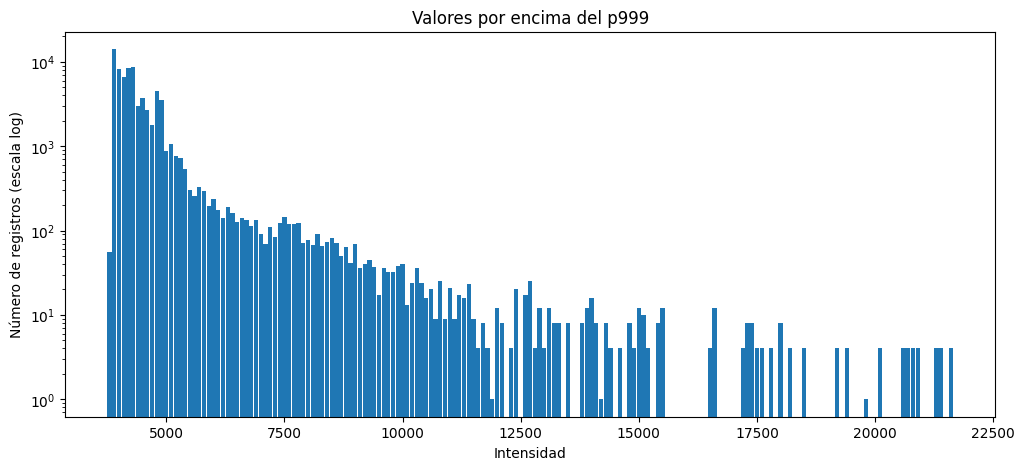

In [5]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

altos = (df.filter(F.col("intensity") > 3888)
           .withColumn("tramo", F.floor(F.col("intensity") / 100) * 100)
           .groupBy("tramo").count()
           .orderBy("tramo")
           .toPandas())

plt.figure(figsize=(12, 5))
plt.bar(altos["tramo"], altos["count"], width=90)
plt.yscale("log")
plt.xlabel("Intensidad")
plt.ylabel("Número de registros (escala log)")
plt.title("Valores por encima del p999")
plt.show()

**Observaciones:**
- Hasta los 10 mil los valores van bajando en forma gradual y continua sin huecos. Son pocos momentos de transito pero muy intensos.
- A partir de 12 mil, la curva se rompe y aparecen huecos, barras aisladas y valores muy dispersos. Esto es señal tipica de errores de medicion. 

Revisaremos si esos valores no estan duplicados. Para eso revisamos la coulmna updated_a 


In [7]:
(df.filter(F.col("intensity") > 15000)
   .select("detector_id", "snapshot_datetime", "detector_updated_at", "intensity")
   .orderBy("detector_id", "snapshot_datetime")
   .show(20, truncate=False))

+-----------+-------------------+-------------------+---------+
|detector_id|snapshot_datetime  |detector_updated_at|intensity|
+-----------+-------------------+-------------------+---------+
|1019       |2023-05-05 12:15:02|null               |16530.0  |
|1019       |2023-05-05 12:30:01|null               |16530.0  |
|1019       |2023-05-05 12:45:01|null               |16530.0  |
|1019       |2023-05-05 13:00:02|null               |16530.0  |
|1019       |2024-03-14 20:15:02|1710453180000000000|20970.0  |
|1019       |2024-03-14 20:30:02|1710453180000000000|20970.0  |
|1019       |2024-03-14 20:45:02|1710453180000000000|20970.0  |
|1019       |2024-03-14 21:00:02|1710453180000000000|20970.0  |
|1418       |2023-06-12 11:15:01|null               |15552.0  |
|1418       |2023-06-12 11:30:01|null               |15552.0  |
|1418       |2023-06-12 11:45:02|null               |15552.0  |
|1418       |2023-06-12 12:00:01|null               |15552.0  |
|1418       |2024-07-15 16:15:01|1721073

In [8]:
print(altos[altos["tramo"] >= 12000].to_string())

     tramo  count
82   12000     12
83   12100      8
84   12300      4
85   12400     20
86   12600     17
87   12700     25
88   12800      4
89   12900     12
90   13000      4
91   13100     12
92   13200      8
93   13300      8
94   13500      8
95   13800      8
96   13900     12
97   14000     16
98   14100      8
99   14200      1
100  14300      8
101  14400      4
102  14600      4
103  14800      8
104  14900      4
105  15000     12
106  15100     10
107  15200      4
108  15400      8
109  15500     12
110  16500      4
111  16600     12
112  17200      4
113  17300      8
114  17400      8
115  17500      4
116  17600      4
117  17800      4
118  18000      8
119  18200      4
120  18500      4
121  19200      4
122  19400      4
123  19800      1
124  20100      4
125  20600      4
126  20700      4
127  20800      4
128  20900      4
129  21300      4
130  21400      4
131  21600      4


Estos numeros muestran que los outliers tiene aproximadamente 4 filas  por cada medicion real. Los conteos parecen estar multiplicados
Esto puede indicar que todo el dataset este igual
Revisamos todo el dataset. Añadimos etiqueta de fecha, agrupamos y contamos


In [9]:
bloque = F.date_trunc("hour", F.col("snapshot_datetime") - F.expr("INTERVAL 15 MINUTES"))

total = df.count()
unicos = df.select("detector_id", bloque.alias("hora"), "intensity").distinct().count()

print(f"Total filas: {total}")
print(f"Mediciones distintas: {unicos}")
print(f"Filas por medición: {total / unicos:.2f}")

Total filas: 106467612
Mediciones distintas: 27597741
Filas por medición: 3.86


**Limpieza a realizar:**
Se comprueba que todo el dataset tiene mediciones repetidas.
Documentaremos este hallazgo con algunos ejemplos.
Limpiaremos estas repeticiones

In [10]:
df_h = df.withColumn("hora", F.date_trunc("hour", F.col("snapshot_datetime") - F.expr("INTERVAL 15 MINUTES")))

# 1. Buscar 3 bloques de 4 capturas con el mismo valor, en 3 espiras distintas
ejemplos = (df_h.filter((F.col("year") == 2024) & (F.col("month") == 3))
                .filter(F.col("intensity") > 0)
                .groupBy("detector_id", "hora")
                .agg(F.count("*").alias("n"),
                     F.countDistinct("intensity").alias("valores_distintos"))
                .filter((F.col("n") == 4) & (F.col("valores_distintos") == 1))
                .dropDuplicates(["detector_id"])
                .limit(3))

# 2. Mostrar las filas completas de esos bloques
(df_h.join(ejemplos.select("detector_id", "hora"), ["detector_id", "hora"])
     .select("detector_id", "snapshot_datetime", "intensity")
     .orderBy("detector_id", "snapshot_datetime")
     .show(truncate=False))

+-----------+-------------------+---------+
|detector_id|snapshot_datetime  |intensity|
+-----------+-------------------+---------+
|2904       |2024-03-07 13:15:01|42.0     |
|2904       |2024-03-07 13:30:05|42.0     |
|2904       |2024-03-07 13:45:02|42.0     |
|2904       |2024-03-07 14:00:02|42.0     |
|3606       |2024-03-02 06:15:02|126.0    |
|3606       |2024-03-02 06:30:01|126.0    |
|3606       |2024-03-02 06:45:03|126.0    |
|3606       |2024-03-02 07:00:01|126.0    |
|829        |2024-03-16 18:15:02|221.0    |
|829        |2024-03-16 18:30:02|221.0    |
|829        |2024-03-16 18:45:01|221.0    |
|829        |2024-03-16 19:00:02|221.0    |
+-----------+-------------------+---------+



**Observacion:**
Los archivos de origen se capturan cada 15 minutos, pero las espiras actualizan su valor una vez por hora. En consecuencia, cada medición aparece repetida en hasta 4 capturas consecutivas. Sobre el total del dataset, las 106.467.612 filas corresponden a 27.597.741 mediciones distintas (3,86 filas por medición), por lo que aproximadamente el 74 % de los registros son copias.

In [26]:
# Veamos latitud y longitud
df.select(F.min("latitude"), F.max("latitude"),
          F.min("longitude"), F.max("longitude")).show()

# ¿Alguna espira tiene más de una ubicación?
(df.groupBy("detector_id")
   .agg(F.countDistinct("latitude", "longitude").alias("ubicaciones"))
   .filter(F.col("ubicaciones") > 1)
   .count())

+------------------+-----------------+-------------------+--------------+
|     min(latitude)|    max(latitude)|     min(longitude)|max(longitude)|
+------------------+-----------------+-------------------+--------------+
|-7.488743884877489|39.53033955329459|-0.4270342963669762|           0.0|
+------------------+-----------------+-------------------+--------------+



572

**Decision:**
Hay errores en las coordenadas. 
Presentan inconsistencias: valores fuera de València (latitud -7,49, longitud 0,0) y 572 espiras con más de una ubicación registrada.
Se decide no incorporar coordenadas a la silver al no formar parte del análisis. 

In [12]:
# Comprobamos si existen registros duplicados
print("Número de combinaciones duplicadas:", df.count() - df.dropDuplicates().count())


Número de combinaciones duplicadas: 0


In [27]:
# Comprobamos si hay dos filas para la misma espira en la misma captura

(df.groupBy("detector_id", "snapshot_datetime").count()
   .filter(F.col("count") > 1)
   .count())

438437

In [28]:
# Combinaciones de espira y captura que aparecen más de una vez
dups = (df.groupBy("detector_id", "snapshot_datetime")
          .agg(F.count("*").alias("filas"),
               F.sum(F.col("intensity").isNull().cast("int")).alias("nulos"))
          .filter(F.col("filas") > 1))

(dups.groupBy(F.year("snapshot_datetime").alias("anio"))
     .agg(F.count("*").alias("combinaciones"),
          F.sum("filas").alias("filas"),
          F.sum("nulos").alias("nulos"))
     .orderBy("anio")
     .show())

+----+-------------+-------+-----+
|anio|combinaciones|  filas|nulos|
+----+-------------+-------+-----+
|2023|       358065|1391996|    0|
|2024|        26278|  69188|53124|
|2025|        54094|3711928|90481|
+----+-------------+-------+-----+



**Comentarios:**
Se detectan espiras que aparecen más de una vez en una misma captura: 358.065 casos en 2023, 26.278 en 2024 y 54.094 en 2025. 

**Limpieza:**
Estos duplicados se eliminan en la limpieza al conservar un único registro por espira y hora.

### Análisis exploratorio preliminar

In [2]:
df = spark.read.parquet("gs://tfm_unir1/trafico/espires_VLC2_unificado")

In [5]:
# Primeras estadísticas descriptivas
from pyspark.sql import functions as F

df_validos = df.filter(
    (F.col("intensity").isNotNull()) & (F.col("intensity") != -1))

# Con outliers
df_validos.select("intensity").summary(
    "count","mean","stddev","min",
    "25%","50%","75%","max").show()

# Sin outliers
df_validos.filter(F.col("intensity")<=12000).select ("intensity").summary(
    "count","mean","stddev","min",
    "25%","50%","75%","max").show()


+-------+------------------+
|summary|         intensity|
+-------+------------------+
|  count|          71002021|
|   mean|436.93600187803105|
| stddev| 589.0431387895662|
|    min|               0.0|
|    25%|              42.0|
|    50%|             210.0|
|    75%|             600.0|
|    max|           21600.0|
+-------+------------------+



+-------+-----------------+
|summary|        intensity|
+-------+-----------------+
|  count|         71001659|
|   mean|436.8612220877825|
| stddev|588.0831200833516|
|    min|              0.0|
|    25%|             42.0|
|    50%|            210.0|
|    75%|            600.0|
|    max|          12000.0|
+-------+-----------------+



- La intensidad presenta una mediana de 210 veh/h y una media de 437 veh/h.  
- La media es mayor que la mediana: esto indica una distribución asimétrica hacia la derecha (muchas horas de poco tráfico y pocas de tráfico muy alto). 
- Anteriormente ya analizamos los outliers, que son aquellos valores superiores a 12000 veh/h (362 registros). Pero como vemos en las mediciones, afectan poco a los estadisticos. 

### Evolución anual del tráfico

In [6]:
from pyspark.sql import functions as F

df_validos.groupBy(
    F.col("year")
).agg(
    F.round(F.avg("intensity"), 2).alias("media_trafico"),
    F.round(F.max("intensity"), 2).alias("maximo_trafico"),
    F.count("*").alias("registros_validos")
).orderBy("year").show(20)

+----+-------------+--------------+-----------------+
|year|media_trafico|maximo_trafico|registros_validos|
+----+-------------+--------------+-----------------+
|2023|       371.37|       21600.0|         31073372|
|2024|        445.8|       20970.0|         23570681|
|2025|       548.71|       17400.0|         16357968|
+----+-------------+--------------+-----------------+



La media anual aumenta de 371 a 549 veh/h entre 2023 y 2025, pero esta diferencia no puede interpretarse como un aumento real del tráfico: cada año incluye un conjunto distinto de espiras y 2025 contiene duplicados. La evolución anual se analizará sobre los datos limpios, con el mismo grupo de espiras y un registro por espira y hora

### Identificación de valores extremos

Esta sección ya fue analizada anteriormente cuando detectamos valores inválidos

### Análisis de un episodio de valor elevado para reafirmar conclusiones anteriores

In [7]:
maximo = df.orderBy(F.desc("intensity")).select("detector_id", "snapshot_datetime", "intensity").first()
print(maximo)

Row(detector_id='320', snapshot_datetime=datetime.datetime(2023, 5, 5, 12, 15, 2), intensity=21600.0)


In [12]:
from datetime import timedelta


df.filter(
    (F.col("detector_id")== maximo["detector_id"])&
    (F.col("snapshot_datetime") >= maximo ["snapshot_datetime"] - timedelta(hours=6)) &
    (F.col("snapshot_datetime") <= maximo ["snapshot_datetime"] + timedelta(hours=6))
).select("snapshot_datetime","intensity"
).orderBy("snapshot_datetime").show(60, truncate=False)

+-------------------+---------+
|snapshot_datetime  |intensity|
+-------------------+---------+
|2023-05-05 06:30:02|335.0    |
|2023-05-05 06:45:02|335.0    |
|2023-05-05 07:00:03|335.0    |
|2023-05-05 07:15:01|1200.0   |
|2023-05-05 07:30:02|1200.0   |
|2023-05-05 07:45:01|1200.0   |
|2023-05-05 08:00:01|1200.0   |
|2023-05-05 08:15:01|3930.0   |
|2023-05-05 08:30:02|3930.0   |
|2023-05-05 08:45:01|3930.0   |
|2023-05-05 09:00:02|3930.0   |
|2023-05-05 09:15:02|3360.0   |
|2023-05-05 09:30:01|3360.0   |
|2023-05-05 09:45:02|3360.0   |
|2023-05-05 10:00:02|3360.0   |
|2023-05-05 10:15:02|2910.0   |
|2023-05-05 10:30:03|2910.0   |
|2023-05-05 10:45:07|2910.0   |
|2023-05-05 11:00:03|2910.0   |
|2023-05-05 11:15:01|3510.0   |
|2023-05-05 11:30:02|3510.0   |
|2023-05-05 11:45:02|3510.0   |
|2023-05-05 12:00:01|3510.0   |
|2023-05-05 12:15:02|21600.0  |
|2023-05-05 12:30:01|21600.0  |
|2023-05-05 12:45:01|21600.0  |
|2023-05-05 13:00:02|21600.0  |
|2023-05-05 13:15:01|2790.0   |
|2023-05

Estudiamos qué ocurrió alrededor del máximo del 5 de mayo de 2023 para comprobar si el tráfico aumentó progresivamente o si fue un pico aislado. 
Las horas anteriores y posteriores registran entre 2400 y 3900 veh/h, y la intensidad vuelve a 2790 veh/h en la hora siguiente. Se trata de un pico aislado, sin evolucion progresiva, la que confirma un error de medicion.

## 3. Caracterizaciones adicionales del conjunto completo 

Hemos hecho un analisis inicial de todo el conjunto de datos. 
Agregamos algunas análisis adicionales que puedan ser de utilidad para el TFM.

### Análisis de cobertura espacial y temporal

In [13]:
# Cobertura general
df_validos.agg(
    F.countDistinct("detector_id").alias("espiras"),
    F.min("snapshot_datetime").alias("primera_fecha"),
    F.max("snapshot_datetime").alias("ultima_fecha")
).show(truncate=False)

+-------+-------------------+-------------------+
|espiras|primera_fecha      |ultima_fecha       |
+-------+-------------------+-------------------+
|1229   |2023-03-09 17:00:02|2025-09-24 00:00:02|
+-------+-------------------+-------------------+



In [16]:
#Cobertura por espira
df_validos.groupBy("detector_id").agg(
    F.min("snapshot_datetime").alias("inicio"),
    F.max("snapshot_datetime").alias("fin"),
    F.count("*").alias("registros")
).orderBy("registros").show(20, truncate=False)

+-----------+-------------------+-------------------+---------+
|detector_id|inicio             |fin                |registros|
+-----------+-------------------+-------------------+---------+
|324        |2023-03-09 17:00:02|2025-04-09 01:00:02|4579     |
|613        |2023-10-24 13:15:02|2025-09-24 00:00:02|10077    |
|1514       |2023-03-09 17:00:02|2025-04-09 01:00:02|16011    |
|2940       |2023-03-09 17:00:02|2023-10-16 03:00:02|18482    |
|4430       |2023-03-09 17:00:02|2023-10-16 03:00:02|19899    |
|3521       |2023-03-09 17:00:02|2023-10-16 03:00:02|19899    |
|3321       |2023-03-09 17:00:02|2023-10-16 03:00:02|19899    |
|5503       |2023-03-09 17:00:02|2023-10-16 03:00:02|19899    |
|3529       |2023-03-09 17:00:02|2023-10-16 03:00:02|19899    |
|5502       |2023-03-09 17:00:02|2023-10-16 03:00:02|19899    |
|3312       |2023-03-09 17:00:02|2023-10-16 03:00:02|19899    |
|2263       |2023-03-09 17:00:02|2023-10-16 03:00:02|19899    |
|2759       |2023-03-09 17:00:02|2023-10

In [18]:
df_validos.groupBy("detector_id").agg(
    F.min("snapshot_datetime").alias("inicio"),
    F.max("snapshot_datetime").alias("fin"),
    F.count("*").alias("registros")
).orderBy(F.desc("registros")).show(20, truncate=False)

+-----------+-------------------+-------------------+---------+
|detector_id|inicio             |fin                |registros|
+-----------+-------------------+-------------------+---------+
|           |2025-01-07 15:15:01|2025-03-15 22:00:02|3373398  |
|922        |2023-03-09 17:00:02|2025-09-24 00:00:02|124159   |
|1531       |2023-03-09 17:00:02|2025-09-24 00:00:02|123076   |
|3036       |2023-03-09 17:00:02|2025-09-24 00:00:02|122765   |
|3030       |2023-03-09 17:00:02|2025-09-24 00:00:02|122413   |
|3031       |2023-03-09 17:00:02|2025-09-24 00:00:02|121477   |
|3035       |2023-03-09 17:00:02|2025-09-24 00:00:02|120233   |
|535        |2023-03-09 17:00:02|2025-09-24 00:00:02|119762   |
|910        |2023-03-09 17:00:02|2025-09-24 00:00:02|119671   |
|2022       |2023-03-09 17:00:02|2025-09-24 00:00:02|119167   |
|2028       |2023-03-09 17:00:02|2025-09-24 00:00:02|118978   |
|2023       |2023-03-09 17:00:02|2025-09-24 00:00:02|116192   |
|2021       |2023-03-09 17:00:02|2025-09

***Observaciones:***
- El conjunto cubre del 9 de marzo de 2023 al 24 de septiembre de 2025, con 1.228 espiras identificadas.
- Las espiras con mejor cobertura acumulan unos 120.000 registros válidos y tienen datos durante todo el periodo.
- Las 188 espiras muertas (identificadas anteriormente) dejan de enviar datos simultáneamente el 16 de octubre de 2023, lo que indica un corte en la fuente.
- Algunas espiras activas hasta 2025 tienen una cobertura muy baja (por ejemplo, la 324 con 4.579 registros) y se revisarán antes de definir el grupo estable.
- Se detectan 3.373.398 registros con identificador de espira vacío, concentrados entre enero y marzo de 2025. 

***Limpieza:***
Con este nuevo hallazgo de espira = "", debemos eliminarlas en el momento de la limpieza porque no se pueden asignar de una manera certera a ninguna espira.

### Evaluación adicional de  calidad de los datos 

In [19]:
# Analizamos ceros en la intensidad
df_validos.agg(
    F.sum((F.col("intensity") == 0).cast("int")).alias("ceros"),
    F.round(F.avg((F.col("intensity") == 0).cast("int")) * 100, 2).alias("pct_ceros")
).show()

+--------+---------+
|   ceros|pct_ceros|
+--------+---------+
|13886152|    19.56|
+--------+---------+



El procentaje de ceros es alto. Analizamos si coincide con horarios nocturnos o si estan asociados a espiras en particular, para determinar si hay problemas de calidad de datos o no.

In [20]:
# Son de noche?
(df_validos.filter(F.col("detector_id") != "")
   .groupBy(F.hour("snapshot_datetime").alias("hora"))
   .agg(F.round(F.avg((F.col("intensity") == 0).cast("int")) * 100, 1).alias("pct_ceros"))
   .orderBy("hora")
   .show(24))

+----+---------+
|hora|pct_ceros|
+----+---------+
|   0|     23.3|
|   1|     29.5|
|   2|     37.2|
|   3|     44.8|
|   4|     47.2|
|   5|     45.5|
|   6|     39.2|
|   7|     25.4|
|   8|     17.3|
|   9|     14.2|
|  10|     12.7|
|  11|     12.0|
|  12|     11.6|
|  13|     11.1|
|  14|     10.8|
|  15|     11.4|
|  16|     12.3|
|  17|     11.7|
|  18|     11.0|
|  19|     10.6|
|  20|     10.7|
|  21|     11.4|
|  22|     13.4|
|  23|     18.3|
+----+---------+



In [21]:
# Provienen de la misma espira?
(df_validos.filter(F.col("detector_id") != "")
   .groupBy("detector_id")
   .agg(F.avg((F.col("intensity") == 0).cast("int")).alias("pct_ceros"))
   .withColumn("grupo", F.when(F.col("pct_ceros") >= 0.9, "casi siempre 0")
                         .when(F.col("pct_ceros") >= 0.5, "más de la mitad 0")
                         .otherwise("normal"))
   .groupBy("grupo").count()
   .show())

+-----------------+-----+
|            grupo|count|
+-----------------+-----+
|más de la mitad 0|   40|
|           normal|  995|
|   casi siempre 0|  193|
+-----------------+-----+



***Observaciones:***
- Hay observaciones en cero que coinciden con horarios nocturnos
- Sin embargo, durante el dia, se mantiene un 11% de ceros, lo que indica espiras que no registran tráfico de forma continua.
- Al analizar el comportamiento de las espiras vemos que 193 tienen valores siempre en 0 y 40 con mas de la mitad en 0. Algunas de estas podrían coincidir con las espiras muertas detectadas anteriormente. Luego de realizar todas las limpiezas, se volverá a revisar.

***Limpieza:***
Luego de limpiar las espiras muertas, se revisaran las que tienen mas del 50% en cero y se eliminarán considerandolas atascadas o inactivas.

### Registros duplicados

Ya fueron analizados anteriormente

### Consistencia de los intervalos temporales

In [23]:
# consistencia de los intervalos temporales
(df.select("snapshot_datetime").distinct()
   .groupBy(F.minute("snapshot_datetime").alias("minuto"))
   .count()
   .orderBy("minuto")
   .show(60))

+------+-----+
|minuto|count|
+------+-----+
|     0|20779|
|     1|   24|
|     2|    9|
|     3|    3|
|    15|21016|
|    16|    2|
|    17|    1|
|    30|21002|
|    31|    3|
|    45|21014|
|    46|    2|
+------+-----+



Las capturas se realizan cada 15 minutos (minutos 0, 15, 30 y 45). Solo 47 capturas (menos del 0,1 %) presentan retrasos de 1 a 3 minutos, que no afectan a la asignación de cada medición a su hora.